In [1]:
import yfinance as yf
import pandas as pd
import numpy as np

In [ ]:
start = '2020-04-28'
end = '2025-07-22'
tickers = ['BTC-USD','XRP-USD','PAXG-USD']
data = yf.download(tickers, start, end)['Close']
data


/tmp/ipython-input-44-178009061.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start, end)['Close']
[*********************100%***********************]  3 of 3 completed


Ticker,BTC-USD,PAXG-USD,XRP-USD
Date,,,
2025-04-28,94978.750000,3340.941895,2.295138
2025-04-29,94284.789062,3316.695801,2.240801
2025-04-30,94207.312500,3284.044189,2.191557
2025-05-01,96492.335938,3249.651855,2.214162
2025-05-02,96910.070312,3255.711182,2.209831
...,...,...,...
2025-07-17,119289.843750,3341.968506,3.495129
2025-07-18,118003.226562,3352.098145,3.418212
2025-07-19,117939.976562,3358.902100,3.429406


In [ ]:
initial_BTC = 100/data['BTC-USD'][0]
initial_XRP = 100/data['XRP-USD'][0]
initial_PAXG = 100/data['PAXG-USD'][0]
data['portfolio_value'] = (initial_BTC*data['BTC-USD'] + initial_XRP*data['XRP-USD'] + initial_PAXG*data['PAXG-USD'])
data['port_returns'] = data['portfolio_value'].pct_change()

data

/tmp/ipython-input-45-794043597.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  initial_BTC = 100/data['BTC-USD'][0]
/tmp/ipython-input-45-794043597.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  initial_XRP = 100/data['XRP-USD'][0]
/tmp/ipython-input-45-794043597.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  initial_PAXG = 100/data['PAXG-USD'][0]


Ticker,BTC-USD,PAXG-USD,XRP-USD,portfolio_value,port_returns
Date,,,,,
2025-04-28,94978.750000,3340.941895,2.295138,300.000000,NaN
2025-04-29,94284.789062,3316.695801,2.240801,296.176151,-0.012746
2025-04-30,94207.312500,3284.044189,2.191557,292.971675,-0.010819
2025-05-01,96492.335938,3249.651855,2.214162,295.332997,0.008060
2025-05-02,96910.070312,3255.711182,2.209831,295.765473,0.001464
...,...,...,...,...,...
2025-07-17,119289.843750,3341.968506,3.495129,377.911137,0.055966
2025-07-18,118003.226562,3352.098145,3.418212,373.508388,-0.011650
2025-07-19,117939.976562,3358.902100,3.429406,374.133174,0.001673


In [ ]:
# data['port_returns'].mean()
sharpe_ratio = ((data['port_returns'].mean() - 0.062/365) / data['port_returns'].std()) *np.sqrt(365)
max_drawdown_series = (data['portfolio_value'].cummax() - data['portfolio_value']) / data['portfolio_value'].cummax()
max_drawdown = max_drawdown_series.max()
print (sharpe_ratio)
print (max_drawdown)

3.4434640661563938
0.08214405129707228


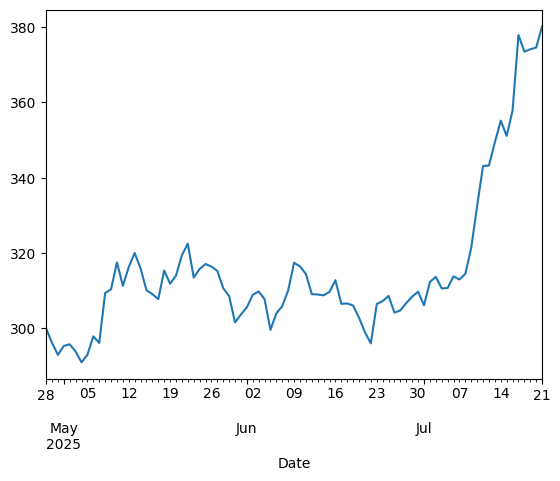

In [ ]:
import matplotlib.pyplot as plt
data['portfolio_value'].plot()
plt.show()